# QC0426 — Measurement

Measure notebook for **QC0426** on the **VTI** rig. Device-specific cells
(tagged `metadata.hera.slot`) are filled from `device_card.md`; every filled
value is marked `# <-- validate`.

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device)
line at bring-up. Cells marked **PATTERN** / **PROPOSAL** carry `<PLACEHOLDER>`
values — review before running.

## Setup

In [2]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep

from hera.analysis import GateCalibration

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205
from drivers.async_station import async_station

In [3]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260619.2-QC0426'

# Connect Instruments

## Magnet

In [4]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.003 Tesla
Current:             : 0.019 A
Voltage:             : 0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [5]:
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')  # <-- verify address
print(heater.sample_temperature())
print(heater.vaporizer_temperature())

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.56s
1.168
0.0


## Lock-ins

In [6]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.10s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [7]:
k_2400 = Keithley_2400('k_2400', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400.mode.set('VOLT')
k_2400.volt.set(0)
k_2400.rangei.set(1e-6)
k_2400.rangev.set(21)
k_2400.volt.step = 0.005
k_2400.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


In [8]:
k_2410 = Keithley_2400('k_2410', 'GPIB0::25::INSTR')  # <-- verify address — Si-gate Keithley
k_2410.mode.set('VOLT')
k_2410.volt.set(0)
k_2410.rangei.set(1e-6)
k_2410.rangev.set(21)
k_2410.volt.step = 0.005
k_2410.volt.inter_delay = 0.01  # Si gate dV/dt pacing - dielectric safety
k_2410.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2410 (serial:1293333, firmware:C30   Mar 17 2006 09:29:29/A02  /J/J) in 0.03s


## DC205 (top gate)

In [9]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — top-gate DC205
dc205.ramp_rate = 2  # V/s

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s


In [10]:
# slot: gate-bindings. hera-session fills the role aliases from the device
# card's wiring (which instrument drives which gate). Mark each filled line
# `# <-- validate`. The dc205_volt wrapper is generic; the k_* role map is
# device-specific.

# Sweepable top-gate parameter — appears in the data as column 'DC_bias'.
def dcbias(vg):
    dc205.ramp_voltage(vg)

dc205_volt = qcodes.Parameter('DC_bias', unit='V', set_cmd=dcbias)

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = dc205_volt   # top gate <- DC205 (fast axis is dc205_volt, NOT k_tg.volt)   # <-- validate
k_bg = k_2400       # back gate <- Keithley 2400                                     # <-- validate
k_si = k_2410       # Si gate   <- Keithley 2410                                     # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [11]:
# slot: gate-validators. hera-session fills the operating limits from the
# device card's gate-operating-limits table; commit EXACTLY the card numbers.
# Mark each filled value `# <-- validate`.
# Instrument-level fences go on the RAW instruments (dc205 / k_2400 / k_2410);
# direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -6.0, +7.0    # top gate (dc205_volt), V    # <-- validate
BG_MIN, BG_MAX = -4.5, +4.5    # back gate (k_2400), V        # <-- validate
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (k_2410), V          # <-- validate
dc205_volt.vals = validators.Numbers(TG_MIN, TG_MAX)
dc205.voltage.vals = validators.Numbers(TG_MIN, TG_MAX)  # instrument-level: direct dc205 calls bypass dc205_volt
k_2400.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
k_2410.volt.vals = validators.Numbers(SI_MIN, SI_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.mag is a qcodes Parameter,
# so this validator rejects any magnet.mag(target) with |B| > B_SESSION_CAP
# before any hardware traffic. (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.mag.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 310.0  # K    # <-- verify
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [12]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [13]:
# slot: geometry. hera-session fills the gate-stack thicknesses from the
# device card (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Mark each filled value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [14]:
# slot: meas-config. hera-session fills sr0_gain and the channel/contact
# assignments from the device card (current channel + gain, provided contact
# configuration). Mark each filled value `# <-- validate`. Always set
# 'comments' per run — structured, current, no inherited text.
meas_config = {
    "sr0": "drain current on B7",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "Rxx T3-T4",  # <-- validate
    "sr2": "Rxx B4-B5",  # <-- validate
    "sr3": "Rxy (Hall) T5-B6",  # <-- validate
    "bias_resistor": 100e6,
    "bias_voltage": sr1.amplitude(),
    "lockin_freq": sr1.frequency(),
    "sr0_sens": sr0.sensitivity(),
    "sr1_sens": sr1.sensitivity(),
    "sr2_sens": sr2.sensitivity(),
    "sr3_sens": sr3.sensitivity(),
    "sample_temperature:": heater.sample_temperature(),  # key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": k_2410.volt(),
    "comments": "<SET PER RUN>",
}


## QSwitch (contact mux) — LIVE

Contact-mux bring-up and the line/breakout maps are device-specific — see the
device card's contact-map section; hera-session fills the cell below from it.
`qsw.reset()` is **always forbidden** — it opens the Si standing closures and
drops the Si gate.

In [15]:
from drivers.QSwitch import QSwitch
from drivers.contact_mux import ContactMux

qsw = QSwitch('qswitch', 'ASRL4::INSTR')  # <-- verify address — QSwitch

# Contact label -> QSwitch line. Si standing-closure lines are EXCLUDED.
LINES = {  # <-- validate (from card contact map)
    "T1": 1,  "T2": 3,  "T3": 4,  "T4": 6,  "T5": 7,  "T6": 12, "T7": 13,
    "B1": 8,  "B2": 17, "B3": 23, "B4": 22, "B5": 20, "B6": 19, "B7": 18, "B8": 15,
}
# Instrument port -> front-panel BNC tap.
BREAKOUTS = {  # <-- validate (from card instrument taps)
    "source": 7, "drain": 8,
    "sr1+": 1, "sr1-": 2, "sr2+": 3, "sr2-": 4, "sr3+": 5, "sr3-": 6,
}
SETTLE_S = 4  # <-- validate (calibrated relay settle)

mux = ContactMux(qsw, lines=LINES, breakouts=BREAKOUTS, settle_s=SETTLE_S)
# qsw.reset() ALWAYS FORBIDDEN — drops the Si gate (standing closures).

Connected to: Quantum Machines QSwitch (serial:37, firmware:2.0) in 0.06s


# HERA — session start (2026-06-19) · QC0426

In [1]:
print('hera-session: kernel bind ok')

hera-session: kernel bind ok


<!-- room health check 2026-06-19 -->

## HERA — E1 kernel-bind probe (read-only)

First autonomous execute. Read-only namespace probe: confirms this kernel carries the
operator's connected instruments, re-reads the committed SAFETIES validators, the magnet
state, base T, current gate setpoints, and the lock-in settling (τ / filter slope) — the
rig card asks these be read and recorded at bring-up since metadata stores them as None.
No instrument writes. ~2 s.


In [16]:
# read-only kernel-bind probe — no instrument writes
print("=== magnet ===")
st = magnet._status()
print("mag() [T]:", magnet.mag(), "| status field [T]:", st['field'],
      "| output:", st['output_enabled'], "| PS heater:", st['persistent_switch'])
print("mag.vals:", magnet.mag.vals)

print("=== thermometry ===")
print("sample_T [K]:", heater.sample_temperature(), "| vaporizer_T [K]:", heater.vaporizer_temperature())

print("=== gate setpoints + validators ===")
print("TG dc205_volt now [V]:", dc205.voltage(), "| dc205_volt.vals:", dc205_volt.vals, "| dc205.voltage.vals:", dc205.voltage.vals)
print("BG k_2400.volt now [V]:", k_2400.volt(), "| k_2400.volt.vals:", k_2400.volt.vals)
print("Si k_2410.volt now [V]:", k_2410.volt(), "| k_2410.volt.vals:", k_2410.volt.vals,
      "| step:", k_2410.volt.step, "| inter_delay:", k_2410.volt.inter_delay)

print("=== lock-ins (settling per rig card) ===")
for nm, sr in [("sr0", sr0), ("sr1", sr1), ("sr2", sr2), ("sr3", sr3)]:
    print(f"{nm}: tau={sr.time_constant()} s | slope={sr.filter_slope()} | sens={sr.sensitivity()} | freq={sr.frequency()} Hz")
print("sr1 AC amplitude [V]:", sr1.amplitude())

print("=== contact mux ===")
print("mux type:", type(mux).__name__, "| settle_s:", mux.settle_s, "| n managed lines:", len(mux.lines))


=== magnet ===


KeyError: 'persistent_switch'

## HERA — E1 kernel-bind probe (read-only, corrected)

Previous probe (cell 30) hit `KeyError: 'persistent_switch'` — wrong status-dict key, no
instrument writes occurred. This version prints the full `_status()` dict and uses `.get()`
so key names are read off the driver rather than assumed. Read-only. ~2 s.


In [17]:
# read-only kernel-bind probe (corrected) — no instrument writes
print("=== magnet ===")
st = magnet._status()
print("status dict:", st)
print("mag() [T]:", magnet.mag(), "| mag.vals:", magnet.mag.vals)

print("=== thermometry ===")
print("sample_T [K]:", heater.sample_temperature(), "| vaporizer_T [K]:", heater.vaporizer_temperature())

print("=== gate setpoints + validators ===")
print("TG dc205.voltage now [V]:", dc205.voltage(), "| dc205_volt.vals:", dc205_volt.vals, "| dc205.voltage.vals:", dc205.voltage.vals)
print("BG k_2400.volt now [V]:", k_2400.volt(), "| k_2400.volt.vals:", k_2400.volt.vals)
print("Si k_2410.volt now [V]:", k_2410.volt(), "| k_2410.volt.vals:", k_2410.volt.vals,
      "| step:", k_2410.volt.step, "| inter_delay:", k_2410.volt.inter_delay)

print("=== lock-ins (settling per rig card) ===")
for nm, sr in [("sr0", sr0), ("sr1", sr1), ("sr2", sr2), ("sr3", sr3)]:
    print(f"{nm}: tau={sr.time_constant()} s | slope={sr.filter_slope()} | sens={sr.sensitivity()} | freq={sr.frequency()} Hz")
print("sr1 AC amplitude [V]:", sr1.amplitude())

print("=== contact mux ===")
print("mux type:", type(mux).__name__, "| settle_s:", mux.settle_s, "| n managed lines:", len(mux.lines))


=== magnet ===
status dict: {'voltage': 0.0003083, 'field': 0.002603972602739726, 'output_enabled': True, 'persistent_switch_on': True, 'loop_mode': 'CC', 'update_mode': 'NORMAL'}
mag() [T]: 0.0026044931506849314 | mag.vals: <Numbers -8.0<=v<=8.0>
=== thermometry ===
sample_T [K]: 1.168 | vaporizer_T [K]: 0.0
=== gate setpoints + validators ===
TG dc205.voltage now [V]: 0.0 | dc205_volt.vals: <Numbers -6.0<=v<=7.0> | dc205.voltage.vals: <Numbers -6.0<=v<=7.0>


BG k_2400.volt now [V]: 0.0 | k_2400.volt.vals: <Numbers -4.5<=v<=4.5>
Si k_2410.volt now [V]: 0.0 | k_2410.volt.vals: <Numbers -50.0<=v<=50.0> | step: 0.005 | inter_delay: 0.01
=== lock-ins (settling per rig card) ===
sr0: tau=0.1 s | slope=24 | sens=0.05 | freq=13.0 Hz
sr1: tau=0.1 s | slope=24 | sens=2e-05 | freq=13.0 Hz
sr2: tau=0.1 s | slope=24 | sens=2e-05 | freq=13.0 Hz


sr3: tau=0.1 s | slope=24 | sens=0.0001 | freq=13.001 Hz
sr1 AC amplitude [V]: 0.5
=== contact mux ===


AttributeError: 'ContactMux' object has no attribute 'settle_s'

## HERA — Gate C (1/2): select provided contact config

Route the provided configuration (device card): source T2(3), drain B7(18), sr1 Rxx
T3–T4(4,6), sr2 Rxx B4–B5(22,20), sr3 Hall T5–B6(7,19). Auto op (in-envelope ContactMux
routing). Si standing closures 16/11 are excluded from the managed `LINES` map and are not
touched; `qsw.reset()` is never called. Verifies routing readback before any sweep. ~4 s settle.


In [18]:
# Gate C contact routing — provided config (device card). Auto op.
mux.select({"source": "T2", "drain": "B7",
            "sr1+": "T3", "sr1-": "T4",
            "sr2+": "B4", "sr2-": "B5",
            "sr3+": "T5", "sr3-": "B6"})
print("routing:", mux._routing)
print("managed lines:", sorted(mux._lines.values()))
print("settle_s:", mux._settle_s)


routing: {'source': ('T2',), 'drain': ('B7',), 'sr1+': ('T3',), 'sr1-': ('T4',), 'sr2+': ('B4',), 'sr2-': ('B5',), 'sr3+': ('T5',), 'sr3-': ('B6',)}
managed lines: [1, 3, 4, 6, 7, 8, 12, 13, 15, 17, 18, 19, 20, 22, 23]
settle_s: 4


## HERA — Gate C (2/2): 1D back-gate liveness sweep

First-session liveness check on the provided contact config (no reference trace to match —
judged on its own terms: contacts respond, lock-ins move, leakage floor clean). Sweep
**BG (k_2400) −4.5 → +4.5 V** at TG=0, Si=0, B≈0, base T. BG chosen over TG so `k_2400.curr`
gives a live leakage readback on the swept gate; geometry prior (c ratio ≈ 1.3) puts the CNP
near Vbg ≈ 0, so this should cross it. BG steps in 5 mV (volt.step=0.005), dielectric-safe.
181 pts, delay 1.0 s = 10·τ (live τ=0.1 s). Est ~3–4 min incl ramp-to-start.

**Preconditions asserted before any move** (raises → no sweep): sample T 1.0–1.4 K, |B|<0.05 T,
TG/Si/BG all ≈ 0 V. **Pass criteria:** Rxx channels (sr1/sr2) finite and varying with a CNP
peak; sr0 drain current responds; |I_bg| leakage well under 1 nA across the sweep.


preconditions OK: {'T': 1.168, 'B': 0.0026047123287671232, 'vtg': 0.0, 'vsi': 0.0, 'vbg': 0.0}
2026-06-19 19:45:59,841 [INFO] Starting sweep with ID 0


2026-06-19 19:45:59,842 [INFO] Minimum duration 0h 3m 1s


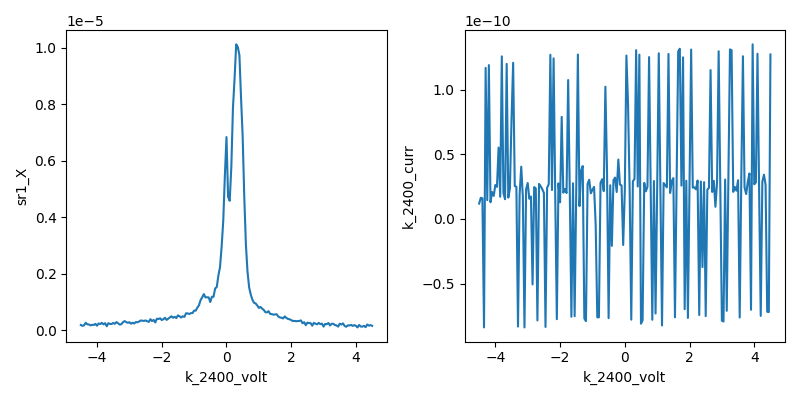

2026-06-19 19:49:49,221 [INFO] Completed in 0h 3m 48s


2026-06-19 19:49:49,222 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619.2-QC0426\data\0\data.tsv.gz


done; BG parked at 1.1125


In [19]:
import numpy as np
# --- preconditions (load-bearing; raise before any hardware move) ---
T   = heater.sample_temperature()
B   = magnet.mag()
vtg = dc205.voltage(); vsi = k_2410.volt(); vbg = k_2400.volt()
assert 1.0 < T < 1.4,   f"sample_T out of range: {T} K"
assert abs(B) < 0.05,   f"|B| not ~0: {B} T"
assert abs(vtg) < 0.01, f"TG not ~0: {vtg} V"
assert abs(vsi) < 0.01, f"Si not ~0: {vsi} V"
assert abs(vbg) < 0.01, f"BG not ~0: {vbg} V"
print("preconditions OK:", dict(T=T, B=B, vtg=vtg, vsi=vsi, vbg=vbg))

# --- station + run ---
meas_config["comments"] = ("Gate C liveness: 1D BG sweep -4.5..4.5 V at TG=0, Si=0, B~0, "
                           "base T; provided contact config (drain B7); first-session, no reference")
s = async_station(meas_config)
s.add_comment('reentry-baseline')
s.add_comment('gateC liveness: BG sweep TG=0 Si=0 B=0')
(s.fp(sr0.X).fp(sr0.P)
  .fp(sr1.X).fp(sr1.P)
  .fp(sr2.X).fp(sr2.P)
  .fp(sr3.X).fp(sr3.P)
  .fp(k_2400.curr).fp(k_2410.curr))
s.plot(k_2400.volt, sr1.X)
s.plot(k_2400.volt, k_2400.curr)
s.sweep(k_2400.volt, np.linspace(-4.5, 4.5, 181), delay=1.0)

# park back to 0
k_2400.volt(0.0)
print("done; BG parked at", k_2400.volt())


In [20]:
# read-only: actual gate + BG state after Gate C park
print("k_2400.volt() get #1:", k_2400.volt())
print("k_2400.volt() get #2:", k_2400.volt())
print("k_2400 setpoint cache:", k_2400.volt.cache.get())
print("k_2400.curr:", k_2400.curr())
print("TG dc205.voltage:", dc205.voltage(), "| Si k_2410.volt:", k_2410.volt())


k_2400.volt() get #1: 0.55625
k_2400.volt() get #2: 0.278125
k_2400 setpoint cache: 0.278125


k_2400.curr: 1.219773e-10
TG dc205.voltage: 0.0 | Si k_2410.volt: 0.0


### HERA — BG park readback check (read-only)
Gate C park printed BG=1.1125 V after `k_2400.volt(0.0)`. Re-reading actual state before any further move.

In [21]:
# set all SR830 time constants to 0.3 s
for sr in (sr0, sr1, sr2, sr3):
    sr.time_constant(0.3)
print("tau:", [sr.time_constant() for sr in (sr0, sr1, sr2, sr3)])
print("slope:", [sr.filter_slope() for sr in (sr0, sr1, sr2, sr3)])


tau: [0.3, 0.3, 0.3, 0.3]
slope: [24, 24, 24, 24]


### debug — set SR830 tau = 0.3 s (all channels)

In [22]:
# read-only k_2400 status (no measurement triggered — avoids disturbing the gate node)
print("OUTP? (1=on)      :", k_2400.ask(':OUTP?'))
print("SOUR:FUNC?        :", k_2400.ask(':SOUR:FUNC?'))
print("SOUR:VOLT:LEV?    :", k_2400.ask(':SOUR:VOLT:LEV?'))      # commanded source voltage
print("SENS:FUNC?        :", k_2400.ask(':SENS:FUNC?'))
print("SENS:CURR:PROT:LEV? (compliance I):", k_2400.ask(':SENS:CURR:PROT:LEV?'))
print("SENS:CURR:PROT:TRIP? (1=in compliance):", k_2400.ask(':SENS:CURR:PROT:TRIP?'))
print("SENS:VOLT:PROT:LEV? (compliance V):", k_2400.ask(':SENS:VOLT:PROT:LEV?'))
print("rangei:", k_2400.rangei(), "| rangev:", k_2400.rangev())


OUTP? (1=on)      : 1
SOUR:FUNC?        : VOLT
SOUR:VOLT:LEV?    : 0.000000E+00
SENS:FUNC?        : "CURR:DC"
SENS:CURR:PROT:LEV? (compliance I): 1.000000E-06
SENS:CURR:PROT:TRIP? (1=in compliance): 0
SENS:VOLT:PROT:LEV? (compliance V): 2.100000E+00
rangei: 1.05e-06 | rangev: 21.0


### debug — k_2400 compliance / output status (read-only SCPI, no measure)

### debug — k_2400 `.volt` get path: averaging-filter check

Driver: `volt.get` = `:READ?` (measured VOLT field), not `:SOUR:VOLT:LEV?`. Hypothesis for the
exact-halving readback: a digital averaging filter (`:SENS:AVER`) whose buffer retained the
sweep's high values and relaxes toward the true 0. This cell reads the filter state and samples
a few fresh `:READ?`s at the now-settled 0 V — expect ~0 and stable if the decay was the filter
relaxing. Read-only (source held at 0, output already on; `:READ?` measures current, harmless).


In [23]:
print("SOUR:VOLT:LEV? (setpoint):", k_2400.ask(':SOUR:VOLT:LEV?'))
print("AVER:STAT? (filter on)  :", k_2400.ask(':SENS:AVER:STAT?'))
print("AVER:COUN? (filter count):", k_2400.ask(':SENS:AVER:COUN?'))
print("AVER:TCON? (mov/rep)    :", k_2400.ask(':SENS:AVER:TCON?'))
print("--- fresh :READ? samples (volt, curr) at settled 0 V ---")
for i in range(6):
    print(f"READ? #{i}:", k_2400.ask(':READ?'))
    time.sleep(0.2)
print("volt.cache (last set/get):", k_2400.volt.cache.get())


SOUR:VOLT:LEV? (setpoint): 0.000000E+00
AVER:STAT? (filter on)  : 1
AVER:COUN? (filter count): 2
AVER:TCON? (mov/rep)    : REP
--- fresh :READ? samples (volt, curr) at settled 0 V ---
READ? #0: +6.953125E-02,+1.270024E-10
READ? #1: +3.476563E-02,+2.805531E-11
READ? #2: +1.738281E-02,-8.099150E-11
READ? #3: +8.691407E-03,+1.988596E-11
READ? #4: +4.345703E-03,-4.659321E-11
READ? #5: +2.172852E-03,+1.651269E-11
volt.cache (last set/get): 0.278125


### debug — k_2400: set averaging filter count to 1

Root cause of the `.volt()` halving was the 2400's averaging filter (`:SENS:AVER` count 2):
`.volt` get = `:READ?` returns a filtered measurement that mixes a stale buffer value with the
fresh sample. Set the count to **1** so each `:READ?` is a single immediate sample (no lag).
Verifies the count readback and confirms no more halving via fresh `:READ?`s at the settled 0 V.


In [24]:
# set k_2400 averaging filter count to 1 (no effective averaging)
k_2400.write(':SENS:AVER:COUN 1')
print("AVER:COUN? now:", k_2400.ask(':SENS:AVER:COUN?'))
print("AVER:STAT?    :", k_2400.ask(':SENS:AVER:STAT?'))
print("SOUR:VOLT:LEV?:", k_2400.ask(':SOUR:VOLT:LEV?'))
print("--- verify no more halving (fresh READ? at 0 V) ---")
for i in range(4):
    print(f"READ? #{i}:", k_2400.ask(':READ?'))
    time.sleep(0.2)


AVER:COUN? now: 1
AVER:STAT?    : 1
SOUR:VOLT:LEV?: 0.000000E+00
--- verify no more halving (fresh READ? at 0 V) ---
READ? #0: +0.000000E+00,+1.821084E-11
READ? #1: +0.000000E+00,+2.431476E-11
READ? #2: +0.000000E+00,+3.165805E-11
READ? #3: +0.000000E+00,+1.954172E-11


### debug — k_2410 (Si) state audit (same driver as k_2400)

k_2410 is the same stock `Keithley_2400` → same `.volt()`=`:READ?` measurement + averaging-filter
footgun. Read-only audit of its filter/source/sense state and a few fresh `:READ?`s to see whether
it halves like k_2400 did (before any fix). Source held at its current setpoint; `:READ?` measures
current, harmless. (Si has standing QSwitch closures 16/11 — untouched; no qsw ops here.)


In [25]:
print("=== k_2410 (Si) state ===")
print("OUTP?         :", k_2410.ask(':OUTP?'))
print("SOUR:FUNC?    :", k_2410.ask(':SOUR:FUNC?'))
print("SOUR:VOLT:LEV?:", k_2410.ask(':SOUR:VOLT:LEV?'))
print("SENS:FUNC?    :", k_2410.ask(':SENS:FUNC?'))
print("AVER:STAT?    :", k_2410.ask(':SENS:AVER:STAT?'))
print("AVER:COUN?    :", k_2410.ask(':SENS:AVER:COUN?'))
print("AVER:TCON?    :", k_2410.ask(':SENS:AVER:TCON?'))
print("CURR:PROT:LEV?:", k_2410.ask(':SENS:CURR:PROT:LEV?'))
print("CURR:PROT:TRIP?:", k_2410.ask(':SENS:CURR:PROT:TRIP?'))
print("rangei:", k_2410.rangei(), "| rangev:", k_2410.rangev())
print("--- fresh :READ? samples (volt, curr) ---")
for i in range(5):
    print(f"READ? #{i}:", k_2410.ask(':READ?'))
    time.sleep(0.2)


=== k_2410 (Si) state ===
OUTP?         : 1
SOUR:FUNC?    : VOLT
SOUR:VOLT:LEV?: 0.000000E+00
SENS:FUNC?    : "CURR:DC"
AVER:STAT?    : 0
AVER:COUN?    : 10
AVER:TCON?    : REP
CURR:PROT:LEV?: 1.050000E-06
CURR:PROT:TRIP?: 0
rangei: 1.05e-06 | rangev: 21.0
--- fresh :READ? samples (volt, curr) ---
READ? #0: +0.000000E+00,-5.024341E-11
READ? #1: +0.000000E+00,-2.752430E-11
READ? #2: +0.000000E+00,-3.496510E-11
READ? #3: +0.000000E+00,-5.717803E-10
READ? #4: +0.000000E+00,-3.288166E-11


### debug — normalize both Keithley averaging filters (k_2400 + k_2410)

Leave the two same-model sources in an identical, explicit state instead of divergent NVRAM
(k_2400 was STAT 1/COUN 2→1; k_2410 STAT 0/COUN 10). Set **both** to `:SENS:AVER:STAT OFF`,
`:SENS:AVER:COUN 1` → averaging explicitly disabled, immediate single-sample `:READ?`. Trades a
hair more per-point leakage-read noise for un-lagged voltage readback (we read gate *state* from
`:SOUR:VOLT:LEV?` anyway). Sources held at their setpoints (both 0 V); no source moves, no QSwitch ops.


In [26]:
# normalize: averaging filter OFF, count 1 on both gate Keithleys
for k in (k_2400, k_2410):
    k.write(':SENS:AVER:STAT OFF')
    k.write(':SENS:AVER:COUN 1')
# verify identical, immediate state
for name, k in [("k_2400", k_2400), ("k_2410", k_2410)]:
    print(f"{name}: STAT={k.ask(':SENS:AVER:STAT?')} COUN={k.ask(':SENS:AVER:COUN?')} "
          f"SOUR:VOLT:LEV={k.ask(':SOUR:VOLT:LEV?')} OUTP={k.ask(':OUTP?')}")
    print("   READ?:", [k.ask(':READ?') for _ in range(3)])


k_2400: STAT=0 COUN=1 SOUR:VOLT:LEV=0.000000E+00 OUTP=1
   READ?: ['+0.000000E+00,+2.151516E-11', '+0.000000E+00,+1.596751E-12', '+0.000000E+00,+2.899612E-11']
k_2410: STAT=0 COUN=1 SOUR:VOLT:LEV=0.000000E+00 OUTP=1
   READ?: ['+0.000000E+00,-3.179037E-11', '+0.000000E+00,-4.687027E-11', '+0.000000E+00,-3.169118E-11']


# HERA — session close (2026-06-19) · QC0426

**Campaign (ABA/ABC stacking ID) not pursued — aborted during Gate C.**

Gate C liveness (run 0, `data/0`) was clean: CNP at Vbg ≈ +0.3 V, contacts alive, leakage
< 135 pA — device healthy. A `k_2400.volt()` readback anomaly (halving after the park) triggered
a debug detour that found and fixed a **Keithley averaging-filter footgun** (`.volt` get = a
filtered `:READ?` measurement, not the setpoint). Both gate Keithleys normalized to
`AVER:STAT OFF / COUN 1`; SR830 τ set to 0.3 s.

**Parked state:** TG / BG / Si at 0 V (output on), magnet ~0 T (PS heater on), no runs in progress.
Full debug trail + TOOLING note + proposed preflight/template fixes in `session_notes.md`.
